# Load dataset, parse relevance list, build vocab

In [26]:
import os

document_contents = {}
queries = []

for document_name in os.listdir("../resources/cranfield/d"):
    with open(f"../resources/cranfield/d/{document_name}") as f:
        doc_id = int(document_name.removesuffix(".txt"))
        document_contents[doc_id] = f.read()

for query_name in os.listdir("../resources/cranfield/q"):
    with open(f"../resources/cranfield/q/{query_name}") as q:
        with open(f"../resources/cranfield/r/{query_name}") as r:
            query_id = int(query_name.removesuffix(".txt"))
            relevant_doc_ids = list(map(int, r.readlines()))
            queries.append(
                (
                    query_id,
                    q.read(),
                    relevant_doc_ids
                )
            )

In [27]:
os.makedirs("../outputs", exist_ok=True)

# Define metrics and helper for plotting

In [ ]:
ks = [1, 3, 5, 10, 15, 25, 35, 50]

In [ ]:
def precision_at_k(retrieved, relevant, k):
    retrieved_k = retrieved[:k]

    relevant_retrieved = sum(
        1 for doc_id in retrieved_k
        if doc_id in relevant
    )

    return relevant_retrieved / k


def recall_at_k(retrieved, relevant, k):
    retrieved_k = retrieved[:k]

    relevant_retrieved = sum(
        1 for doc_id in retrieved_k
        if doc_id in relevant
    )

    return relevant_retrieved / len(relevant)


def f1_score(precision, recall):
    if precision + recall == 0:
        return 0

    return 2 * precision * recall / (precision + recall)

# find position of first relevant document in results
def reciprocal_rank(retrieved, relevant):
    for rank, doc_id in enumerate(retrieved, start=1):
        if doc_id in relevant:
            return 1 / rank

    return 0

In [ ]:
import numpy as np
# for each of ks compute avg precision, recall, f1 across all queries
def evaluate_similarity_matrix(
        document_ids,
        similarity_matrix,
        larger_is_better=True
):
    precision_scores = {k: [] for k in ks}
    recall_scores = {k: [] for k in ks}
    f1_scores = {k: [] for k in ks}

    reciprocal_ranks = []

    for q_idx, (query_id, _, relevant_docs) in enumerate(queries):
        relevant_docs = set(relevant_docs)
        scores = similarity_matrix[q_idx]

        if larger_is_better:
            ranked_indices = np.argsort(scores)[::-1]
        else:
            ranked_indices = np.argsort(scores)

        ranked_doc_ids = [
            document_ids[idx]
            for idx in ranked_indices
        ]

        for k in ks:
            precision = precision_at_k(
                ranked_doc_ids,
                relevant_docs,
                k
            )

            recall = recall_at_k(
                ranked_doc_ids,
                relevant_docs,
                k
            )

            f1 = f1_score(precision, recall)

            precision_scores[k].append(precision)
            recall_scores[k].append(recall)
            f1_scores[k].append(f1)


        reciprocal_ranks.append(
            reciprocal_rank(
                ranked_doc_ids,
                relevant_docs
            )
        )

    avg_precision = [
        np.mean(precision_scores[k])
        for k in ks
    ]

    avg_recall = [
        np.mean(recall_scores[k])
        for k in ks
    ]

    avg_f1 = [
        np.mean(f1_scores[k])
        for k in ks
    ]

    mrr = np.mean(reciprocal_ranks)

    return {
        "ks": ks,
        "precision": avg_precision,
        "recall": avg_recall,
        "f1": avg_f1,
        "mrr": mrr
    }

In [ ]:
import matplotlib.pyplot as plt
def plot_results(results, title):
    ks = results["ks"]
    plt.figure(figsize=(8, 5))
    plt.plot(
        ks,
        results["precision"],
        marker="o",
        label="Precision@k"
    )

    plt.plot(
        ks,
        results["recall"],
        marker="o",
        label="Recall@k"
    )

    plt.plot(
        ks,
        results["f1"],
        marker="o",
        label="F1@k"
    )

    plt.xlabel("k")
    plt.ylabel("Score")

    plt.title(
        f"{title}\nMRR={results['mrr']:.4f}"
    )

    plt.grid(True)
    plt.legend()
    plt.show()

# Binary vector representation

In [28]:
from sklearn.feature_extraction.text import CountVectorizer

binary_vectorizer = CountVectorizer(binary=True)

document_matrix = binary_vectorizer.fit_transform(
    document_contents.values()
)

query_matrix = binary_vectorizer.transform(
    [query_text for _, query_text, _ in queries]
)

In [29]:
feature_names = binary_vectorizer.get_feature_names_out()
for f in feature_names[510:520]:
    print(f)

ability
abilityto
abillowing
ablade
ablating
ablatingmaterial
ablatingsurfaces
ablation
ablationof
ablationover


## Compute cosine and Euclidean similarities

In [30]:
from sklearn.metrics.pairwise import cosine_similarity, euclidean_distances

cosine_sim = cosine_similarity(query_matrix, document_matrix)
euclidean_sim = euclidean_distances(query_matrix, document_matrix)

## Build results csv

In [31]:
import pandas as pd

rows = []

for q_idx, q_tuple in enumerate(queries):
    for d_idx, d_id in enumerate(document_contents.keys()):
        rows.append({
            "query_id": q_tuple[0],
            "document_id": d_id,
            "is_relevant": d_id  in q_tuple[2],
            "cosine": cosine_sim[q_idx][d_idx],
            "euclidean": euclidean_sim[q_idx][d_idx]
        })

df = pd.DataFrame(rows)
df.to_csv("../outputs/binary_similarity_results.csv", index=False)
df.head()

,query_id,document_id,is_relevant,cosine,euclidean
0,1,1,False,0.000000,9.486833
1,1,10,False,0.000000,7.000000
2,1,100,False,0.051640,11.532563
3,1,1000,False,0.027156,11.090537
4,1,1001,False,0.000000,9.110434


## Metrics

In [53]:
cosine_results = evaluate_similarity_matrix(
    list(document_contents.keys()),
    cosine_sim,
    larger_is_better=True
)
print("Cosine MRR:", cosine_results["mrr"])

Cosine MRR: 0.479598152637297


In [54]:
euclidean_results = evaluate_similarity_matrix(
    list(document_contents.keys()),
    euclidean_sim,
    larger_is_better=False
)

print("Euclidean MRR:", euclidean_results["mrr"])

Euclidean MRR: 0.044940405001506034


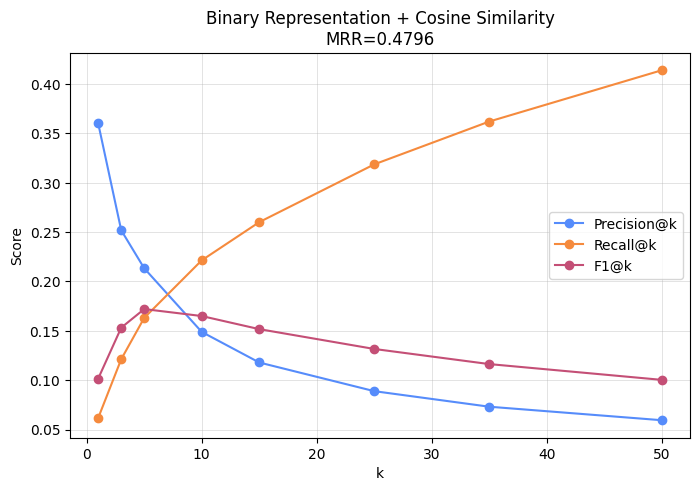

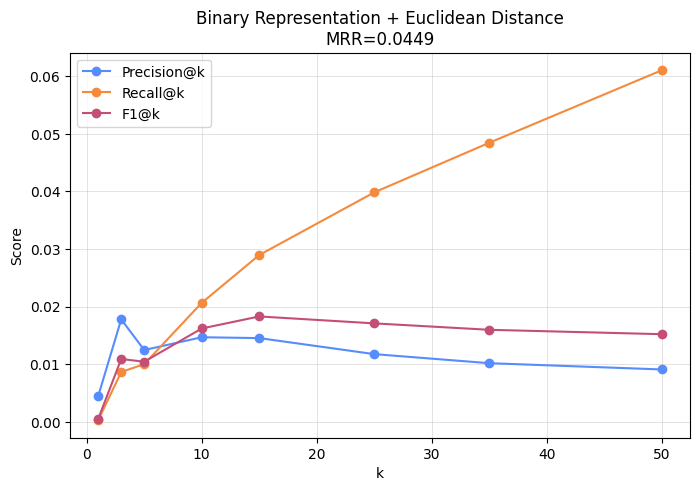

In [55]:
plot_results(
    cosine_results,
    "Binary Representation + Cosine Similarity"
)

plot_results(
    euclidean_results,
    "Binary Representation + Euclidean Distance"
)

# TF

In [62]:
tf_vectorizer = CountVectorizer(binary=False)

document_matrix = tf_vectorizer.fit_transform(
    document_contents.values()
)
query_matrix = tf_vectorizer.transform(
    [query_text for _, query_text, _ in queries]
)


cosine_sim = cosine_similarity(query_matrix, document_matrix)
euclidean_sim = euclidean_distances(query_matrix, document_matrix)

## Build csv

In [63]:
rows = []
for q_idx, q_tuple in enumerate(queries):
    for d_idx, d_id in enumerate(document_contents.keys()):
        rows.append({
            "query_id": q_tuple[0],
            "document_id": d_id,
            "is_relevant": d_id  in q_tuple[2],
            "cosine": cosine_sim[q_idx][d_idx],
            "euclidean": euclidean_sim[q_idx][d_idx]
        })
df = pd.DataFrame(rows)

df.to_csv(
    "../outputs/tf_similarity_results.csv",
    index=False
)

df.head()

,query_id,document_id,is_relevant,cosine,euclidean
0,1,1,False,0.000000,19.974984
1,1,10,False,0.000000,9.643651
2,1,100,False,0.084875,30.512293
3,1,1000,False,0.013358,21.840330
4,1,1001,False,0.000000,17.521415


## Metrics

In [64]:
cosine_results = evaluate_similarity_matrix(
    list(document_contents.keys()),
    cosine_sim,
    larger_is_better=True
)

euclidean_results = evaluate_similarity_matrix(
    list(document_contents.keys()),
    euclidean_sim,
    larger_is_better=False
)


print("TF + Cosine MRR:", cosine_results["mrr"])

print("TF + Euclidean MRR:", euclidean_results["mrr"])

TF + Cosine MRR: 0.40448369727883954
TF + Euclidean MRR: 0.04345530632833024


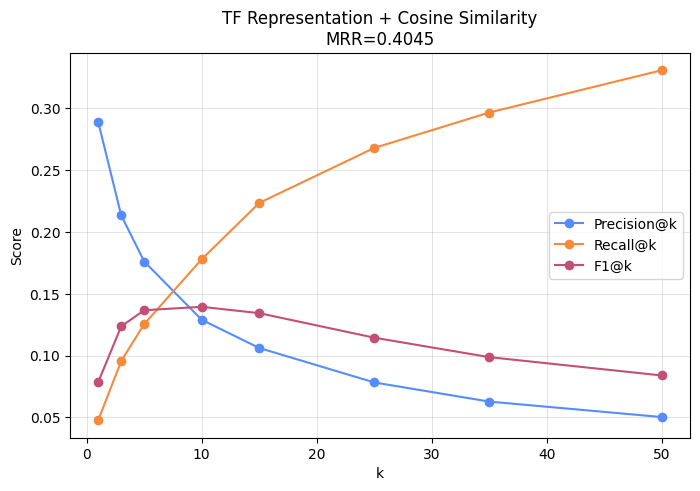

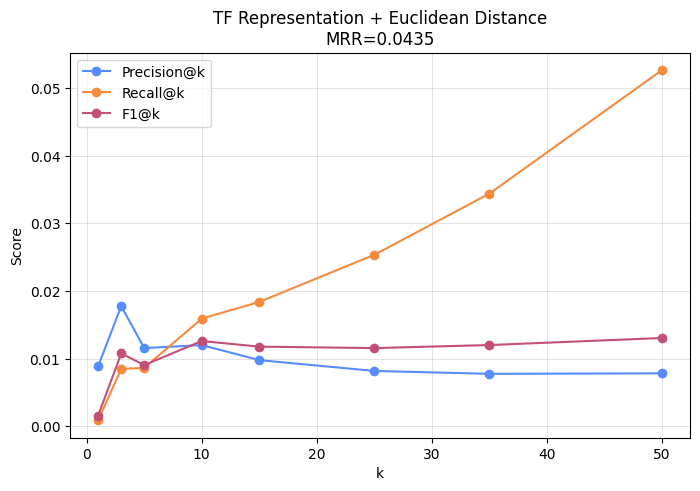

In [65]:
plot_results(
    cosine_results,
    "TF Representation + Cosine Similarity"
)

plot_results(
    euclidean_results,
    "TF Representation + Euclidean Distance"
)

# Tf-idf

In [66]:
from sklearn.feature_extraction.text import TfidfVectorizer
tfidf_vectorizer = TfidfVectorizer()
document_matrix = tfidf_vectorizer.fit_transform(
    document_contents.values()
)
query_matrix = tfidf_vectorizer.transform(
    [query_text for _, query_text, _ in queries]
)


cosine_sim = cosine_similarity(query_matrix, document_matrix)
euclidean_sim = euclidean_distances(query_matrix, document_matrix)

## Build csv

In [68]:
rows = []
for q_idx, q_tuple in enumerate(queries):
    for d_idx, d_id in enumerate(document_contents.keys()):
        rows.append({
            "query_id": q_tuple[0],
            "document_id": d_id,
            "is_relevant": d_id  in q_tuple[2],
            "cosine": cosine_sim[q_idx][d_idx],
            "euclidean": euclidean_sim[q_idx][d_idx]
        })
df = pd.DataFrame(rows)

df.to_csv(
    "../outputs/tf_similarity_results.csv",
    index=False
)

df.head()

,query_id,document_id,is_relevant,cosine,euclidean
0,1,1,False,0.000000,1.414214
1,1,10,False,0.000000,1.414214
2,1,100,False,0.086719,1.351504
3,1,1000,False,0.003271,1.411899
4,1,1001,False,0.000000,1.414214


## Metrics

In [69]:
cosine_results = evaluate_similarity_matrix(
    list(document_contents.keys()),
    cosine_sim,
    larger_is_better=True
)

euclidean_results = evaluate_similarity_matrix(
    list(document_contents.keys()),
    euclidean_sim,
    larger_is_better=False
)


print("TF + Cosine MRR:", cosine_results["mrr"])

print("TF + Euclidean MRR:", euclidean_results["mrr"])

TF + Cosine MRR: 0.6718107182713381
TF + Euclidean MRR: 0.2573499398556413


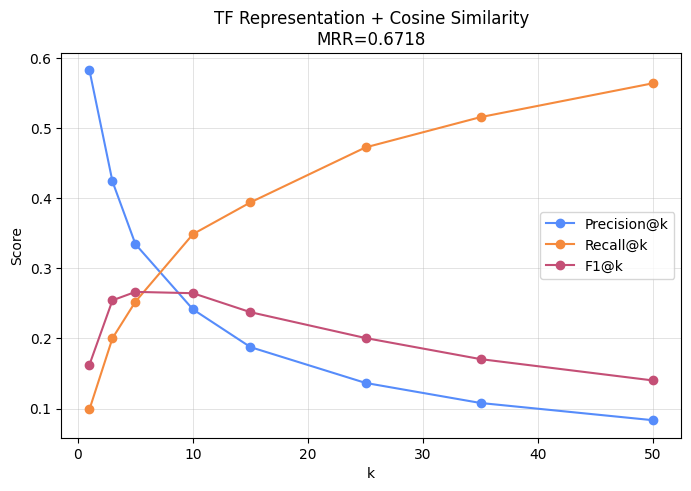

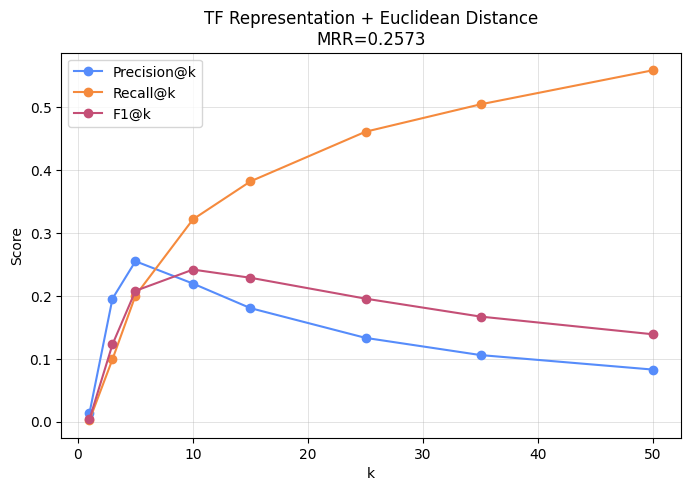

In [70]:
plot_results(
    cosine_results,
    "TF Representation + Cosine Similarity"
)

plot_results(
    euclidean_results,
    "TF Representation + Euclidean Distance"
)